In [69]:
import pandas as pd

prediction_analysis = pd.DataFrame({
    "actual": y_val.values,
    "probability": y_val_proba
})

prediction_analysis.sort_values(
    "probability",
    ascending=False
).head(20)

,actual,probability
7148,1,1.000000
8945,1,1.000000
5249,1,1.000000
15537,1,1.000000
21770,1,1.000000
10022,1,0.999999
7041,0,0.999972
9983,0,0.999912
28137,1,0.999529
21871,1,0.999245


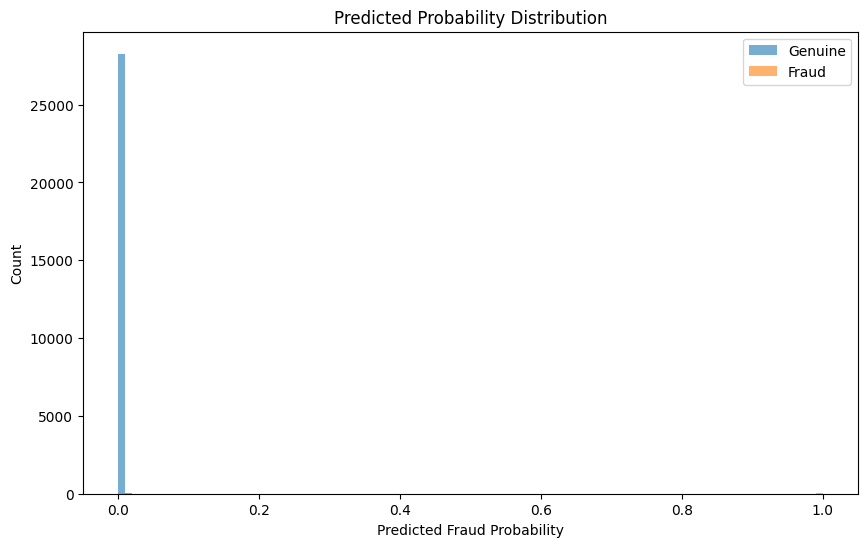

In [70]:
plt.figure(figsize=(10, 6))

plt.hist(
    y_val_proba[y_val.values == 0],
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    y_val_proba[y_val.values == 1],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Count")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [72]:
baseline_results = {
    "model": "Logistic Regression",
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "roc_auc": roc_auc,
    "pr_auc": pr_auc
}

baseline_results

{'model': 'Logistic Regression',
 'precision': 0.8666666666666667,
 'recall': 0.5416666666666666,
 'f1': 0.6666666666666666,
 'roc_auc': np.float64(0.9314724919093852),
 'pr_auc': np.float64(0.6370669816765189)}

Strong Classical ML: Tree-Based Models

Now we move from a linear decision boundary to nonlinear feature interactions.

Your Logistic Regression assumes roughly:

$$ \text{logit}(P(Fraud)) = w_0+w_1X_1+\cdots+w_nX_n $$

But fraud patterns can involve interactions such as:

V17 + V14 + V12 + Amount

rather than each feature independently determining fraud.

We'll test Random Forest first, then move to a gradient-boosting model.

In [73]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained.")

Random Forest trained.


In [74]:
y_val_rf_proba = rf_model.predict_proba(X_val)[:, 1]

y_val_rf_pred = (y_val_rf_proba >= 0.5).astype(int)

In [75]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_precision = precision_score(y_val, y_val_rf_pred)
rf_recall = recall_score(y_val, y_val_rf_pred)
rf_f1 = f1_score(y_val, y_val_rf_pred)

rf_roc_auc = roc_auc_score(y_val, y_val_rf_proba)
rf_pr_auc = average_precision_score(y_val, y_val_rf_proba)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_rf_pred))

print("\nPrecision:", rf_precision)
print("Recall:", rf_recall)
print("F1:", rf_f1)
print("ROC-AUC:", rf_roc_auc)
print("PR-AUC:", rf_pr_auc)

Confusion Matrix:
[[28324     1]
 [   14    34]]

Precision: 0.9714285714285714
Recall: 0.7083333333333334
F1: 0.8192771084337349
ROC-AUC: 0.9226003971756398
PR-AUC: 0.765758587063282


In [76]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    },
    {
        "Model": "Random Forest",
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC-AUC": rf_roc_auc,
        "PR-AUC": rf_pr_auc
    }
])

comparison

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.866667,0.541667,0.666667,0.931472,0.637067
1,Random Forest,0.971429,0.708333,0.819277,0.922600,0.765759


In [77]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(15)

,0
V17,0.149238
V12,0.135484
V14,0.123744
V10,0.086863
V11,0.064675
V16,0.061667
V9,0.038424
V7,0.028406
V18,0.027994
V4,0.026341


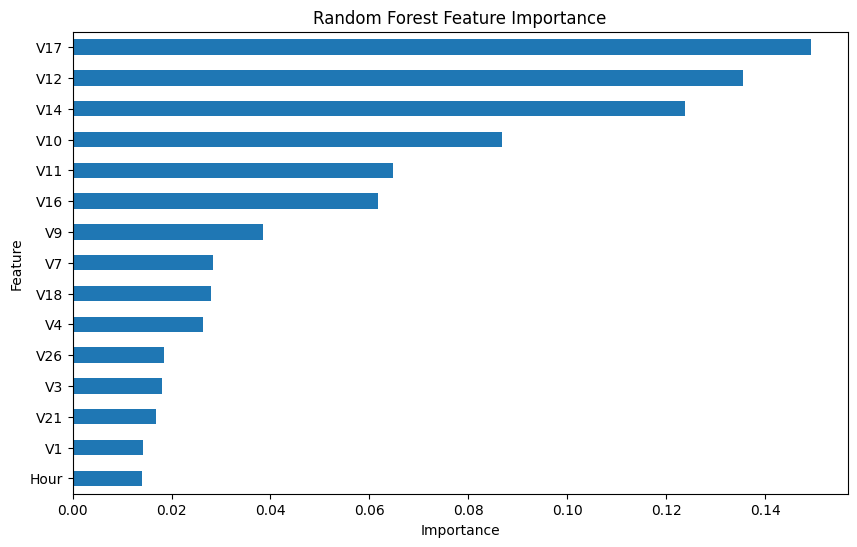

In [78]:
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [79]:
print("Top RF features:")
print(feature_importance.head(15))

Top RF features:
V17     0.149238
V12     0.135484
V14     0.123744
V10     0.086863
V11     0.064675
V16     0.061667
V9      0.038424
V7      0.028406
V18     0.027994
V4      0.026341
V26     0.018381
V3      0.018123
V21     0.016914
V1      0.014226
Hour    0.013965
dtype: float64


In [80]:
!pip install -q xgboost

In [81]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained.")

XGBoost trained.


In [82]:
eval_metric="aucpr"

In [83]:
y_val_xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

y_val_xgb_pred = (y_val_xgb_proba >= 0.5).astype(int)

xgb_precision = precision_score(y_val, y_val_xgb_pred)
xgb_recall = recall_score(y_val, y_val_xgb_pred)
xgb_f1 = f1_score(y_val, y_val_xgb_pred)

xgb_roc_auc = roc_auc_score(y_val, y_val_xgb_proba)
xgb_pr_auc = average_precision_score(y_val, y_val_xgb_proba)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_xgb_pred))

print("\nPrecision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1:", xgb_f1)
print("ROC-AUC:", xgb_roc_auc)
print("PR-AUC:", xgb_pr_auc)

Confusion Matrix:
[[28325     0]
 [   13    35]]

Precision: 1.0
Recall: 0.7291666666666666
F1: 0.8433734939759037
ROC-AUC: 0.9656656369520447
PR-AUC: 0.8084769008150575


In [84]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    },
    {
        "Model": "Random Forest",
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC-AUC": rf_roc_auc,
        "PR-AUC": rf_pr_auc
    },
    {
        "Model": "XGBoost",
        "Precision": xgb_precision,
        "Recall": xgb_recall,
        "F1": xgb_f1,
        "ROC-AUC": xgb_roc_auc,
        "PR-AUC": xgb_pr_auc
    }
])

comparison.sort_values("PR-AUC", ascending=False)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
2,XGBoost,1.000000,0.729167,0.843373,0.965666,0.808477
1,Random Forest,0.971429,0.708333,0.819277,0.922600,0.765759
0,Logistic Regression,0.866667,0.541667,0.666667,0.931472,0.637067


What Stage 5 teaches you

You are now comparing three fundamentally different approaches:

                 Model
                   │
        ┌──────────┼──────────┐
        ↓          ↓          ↓
 Logistic       Random      XGBoost
Regression      Forest
        │          │          │
      Linear     Bagging    Boosting
        │          │          │
        └──────────┼──────────┘
                   ↓
             Fraud probability
                   ↓
              PR-AUC

Your current benchmark is:

Logistic Regression → PR-AUC = 0.6371

Now we want to see how much nonlinear modeling improves that.